# 02: Baselines on the validation split

Builds the forecast samples, runs the two baselines, and scores them with the standalone
harness. Every later model has to beat these numbers on the same cases.

All the logic lives in `src/cyclone/`. This notebook only calls it in order:
load → samples → forecast → score → look at the result.
`docs/components.md` explains each module.

**The test split stays locked.** Test start times are counted to check the samples, but
no forecast is made for them here. Test scores happen once, at the end of Project 1.

**Running locally:** use the `cyclone` kernel after `pip install -e .`. Run notebook 01
first, because this one reads `ni_clean.parquet`.

**Running on Colab:** run these in a first cell:

```python
!git clone https://github.com/Anshuman-Alok-Gupta/Cyclone_Project.git
!pip install -e Cyclone_Project
```

Then choose *Runtime → Restart session*, because Python only finds a newly installed
editable package when it starts. After the restart, run this before the cells below:

```python
from google.colab import drive
drive.mount("/content/drive")

import os
os.environ["CYCLONE_DATA_DIR"] = "/content/drive/MyDrive/cyclone-project/data"
```

In [1]:
import pandas as pd

from cyclone import config
from cyclone.baselines import fit_cliper, persistence, predict_cliper
from cyclone.checks import check_expected, check_samples
from cyclone.plotting import plot_error_by_lead, plot_forecasts
from cyclone.samples import make_init_times, make_truth
from cyclone.scoring import score, summarize

## Load

The cleaned table from notebook 01, checked again in case it's out of date.

In [2]:
df = pd.read_parquet(config.ni_clean_path())
check_expected(df)

Counts match: 5,694 rows, 258 storms, 184/27/47 train/val/test.


## Build the samples

`truth` holds where each storm really was. `init_times` holds every fix with a full 24 h of
history, matched by timestamp, and has no future positions in it.

Each lead time has fewer cases than the last, because storms end. This stops with an
error if any count differs from the verified ones.

In [3]:
truth = make_truth(df)
init_times = make_init_times(df)
check_samples(init_times, truth)

Sample counts match: 4,678 init times.
  train 3,203 init times; cases +24 h 2,515, +48 h 1,869, +72 h 1,324
  val     542 init times; cases +24 h 438, +48 h 340, +72 h 256
  test    933 init times; cases +24 h 749, +48 h 578, +72 h 430


## Run the baselines

CLIPER is fitted inside `fit_cliper` on train storms only, whatever table it's given.
Forecasts are then made for validation start times only.

In [4]:
val = init_times[init_times["split"] == "val"]

cliper_models = fit_cliper(init_times, truth)
forecasts = pd.concat([persistence(val), predict_cliper(cliper_models, val)], ignore_index=True)
forecasts.head()

CLIPER +24 h: fitted on 2,515 train cases
CLIPER +48 h: fitted on 1,869 train cases
CLIPER +72 h: fitted on 1,324 train cases


,model,SID,init_time,lead_h,lat,lon
0,persistence,2013130N04093,2013-05-10 18:00:00,24,8.8,89.4
1,persistence,2013130N04093,2013-05-11 00:00:00,24,10.5,87.7
2,persistence,2013130N04093,2013-05-11 06:00:00,24,11.6,85.8
3,persistence,2013130N04093,2013-05-11 12:00:00,24,11.6,84.9
4,persistence,2013130N04093,2013-05-11 18:00:00,24,11.3,85.3


## Score

Both baselines forecast every start time at every lead time. Where the storm had ended or
left the basin by then there's nothing to compare with, so those forecasts are counted and
kept with a blank error, not dropped.

In [5]:
scored = score(forecasts, truth)
summary = summarize(scored, homogeneous=True)
summary.round(1)

cliper: scored 1,034 of 1,626 forecasts; 592 had no matching truth
persistence: scored 1,034 of 1,626 forecasts; 592 had no matching truth


Homogeneous comparison: kept 2,068 of 2,068 scored forecasts, the cases all 2 models have.


,model,lead_h,count,mean_km,median_km
0,cliper,24,438,129.0,118.4
1,cliper,48,340,289.0,267.0
2,cliper,72,256,459.1,423.7
3,persistence,24,438,137.6,123.6
4,persistence,48,340,319.7,281.9
5,persistence,72,256,509.8,468.6


## Mean error against lead time

JTWC-warned systems in the North Indian Ocean, validation seasons 2013–2017. Both lines
use identical cases.

CLIPER is ahead at every lead time. Persistence can only continue a straight line, while
CLIPER's fit can also lean on where the storm is and the time of year. Validation is only
27 storms, and fixes from one storm are closely related, so a gap this size is a guide and
not a precise measurement.

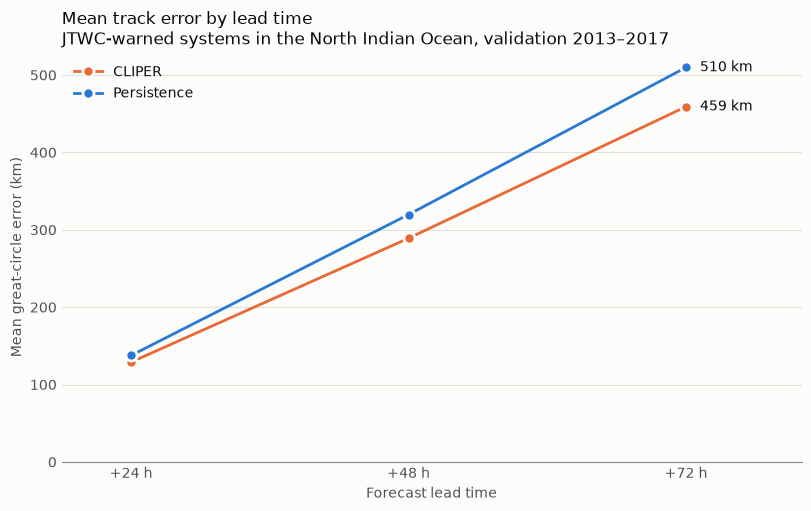

In [6]:
plot_error_by_lead(
    summary,
    title="Mean track error by lead time\n"
    "JTWC-warned systems in the North Indian Ocean, validation 2013–2017",
);

## One storm: Cyclone Hudhud, 2014

Hudhud crossed the Bay of Bengal and hit Visakhapatnam on 12 October 2014. The start time
below, 00Z on 9 October, is about three days before that. It was chosen before looking at
any errors, so it isn't a flattering pick.

On the map, each coloured line has three dots: the forecast at +24, +48 and +72 h, in that
order from the start. Compare each one with the labelled black dot for the same lead time.

One forecast is an illustration, not evidence: the table above is the result. The map is
here to check that the forecasts leave from the right place and head the right way.

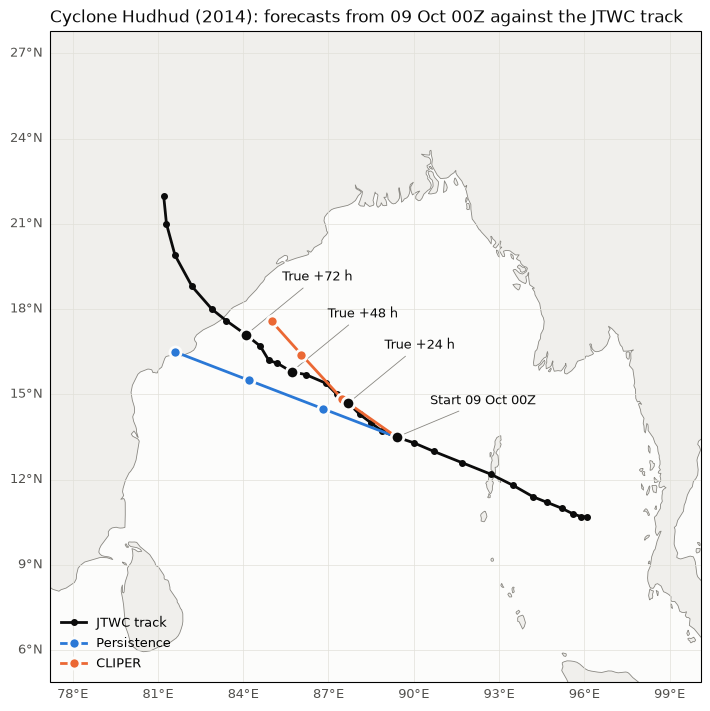

In [7]:
hudhud = df[(df["NAME"] == "HUDHUD") & (df["SEASON"] == 2014)]
sid = hudhud["SID"].iloc[0]
start = pd.Timestamp("2014-10-09 00:00")

plot_forecasts(
    truth,
    forecasts,
    sid=sid,
    init_time=start,
    title="Cyclone Hudhud (2014): forecasts from 09 Oct 00Z against the JTWC track",
);

In [8]:
from_start = scored[(scored["SID"] == sid) & (scored["init_time"] == start)]
from_start.pivot(index="lead_h", columns="model", values="error_km").round(1)

model,cliper,persistence
lead_h,,
24,29.8,99.4
48,76.6,164.0
72,109.3,274.4
